### Libraries ###

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import Boltzmann as kB
from scipy import stats
from scipy.optimize import curve_fit
from numpy import pi
import numpy.random as rnd
import time

### Averaged dispacement ###

In [2]:
def aved_dr(r, tau, show=False):
    #r = np.array([x_pos, y_pos])
    # print("Shape of r before diff:", r.shape)
    dr = r # IF AVED(DR), NO NEED FOR: np.diff(r)  
    deg = np.shape(r)[0]                                            # check if 1d or 2d or 3d
    N_steps = np.shape(r)[1]

    bin_num = int((1 + 3.322*np.log(N_steps))//1) # 'auto'                   # sturges rule for histogram binning 
        
    var = 0
    for i in range(deg):
        dimension = 'x' if i == 0 else 'y'
        
        plt.figure(figsize=(6,3))                                   # displacement v frequency histogram
        r_counts,bins, p = plt.hist(dr[i], bins=bin_num,color = 'blue', density=False, stacked=True) 
        plt.xlabel("Displacement along " + dimension + " ($m$)")
        plt.ylabel("Frequency")
        plt.xlim([bins[0], bins[-1]])
        plt.ylim([0, max(r_counts) * 1.2])
                                        
        lnspc = np.linspace(bins[0], bins[-1], 100)                 # with spacing equal to len(dr[0])

        m, s = stats.norm.fit(dr[i])                                # m = mean ; s = std
        pdf_g = stats.norm.pdf(lnspc, m, s) * max(r_counts) / max(stats.norm.pdf(lnspc, m, s))     # normal distribution (linspace, mean, std) 
        plt.plot(lnspc, pdf_g, "--",                                # normal distribution curve plot
                    label = f"Mean: {m:.2e}; Var: {s**2:.2e}"
)

        plt.legend(loc="upper right")
        if show: 
            plt.show()
        plt.close()
        var += s*s                                                 # var is std squared; summing for each deg

    D = var/(2*deg*tau)
    return D                                            # formula        

#aved(r_of_5)


### Time Averaged (MSD PLOT) ###

In [3]:
def timeaved(r, tau, fit_points = 10, sampl_points = -1, return_vals = False, show=False):  
    deg = np.shape(r)[0]
    tau_arr = np.arange(tau, tau*(fit_points+0.5), tau)             # change in tau; +0.5 to include last fit point
    expMSD_tau, expMSD_tau_std = [], []
    
    for skip in range(1, fit_points+1):                                  # how many tau values to change ; 10 fitpoints = t to 10t
        
        if skip == 0: dr = np.diff(r[:, :sampl_points])             
        else: dr = np.diff(r[:, ::skip][:, :sampl_points])          # skipping timesteps
        
        dr_sq = (dr[0]**2) + (dr[1]**2)                             # displacement**2
    
        expMSD_tau.append(np.mean(dr_sq))                           # mean of squared displacement
        expMSD_tau_std.append(np.std(dr_sq))
        
    expMSD_tau = np.array(expMSD_tau)
    expMSD_tau_std = np.array(expMSD_tau_std)
    
    opt, cov = curve_fit(linear_slope, tau_arr, expMSD_tau)         # fitting
    D = opt[0]/(2*deg)                                              # opt[0] is slope ; opt[1] is y-int = 0      
    equation = f'y = {opt[0]:.2e}x'
    plt.figure(figsize=(6,6))
    plt.plot(tau_arr, expMSD_tau, 'o', color='blue', label="Expt MSD")
    plt.plot(tau_arr, linear_slope(tau_arr, *opt), '--', label="Fitted MSD", color='C1',)
    plt.plot([], [], 'none',label = equation)
    #plt.errorbar(tau_arr, expMSD_tau, yerr=expMSD_tau_std, fmt='o', color='C0')
    plt.xlabel("Sampling Time Interval, $\\tau$ ($s$)")
    plt.ylabel("Mean Squared Displacement ($m^2$)")
    plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0))
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    plt.legend()
    if show: plt.show()
    plt.close()
    
    if return_vals: 
        return D, tau_arr, expMSD_tau, dr, dr_sq#, expMSD_tau_std, tau_arr
    else: 
        return D
    
def linear_slope(x, m): 
    
    return (m*x)  

### Finding the DR for target particle ###

In [4]:
def find_dr_for_target(target, particle_count, lines):
    target_disp_x = []
    target_disp_y = []

    i = 0
    while i < len(lines):
        if lines[i].startswith("ITEM: TIMESTEP"):
            timestep = int(lines[i+1].strip())  # Extract the timestep value
            i += 4  # Skip to "ITEM: NUMBER OF ATOMS", then "BOX BOUNDS"
            
            i += 4  # Skip box bounds (3 lines) and move to "ITEM: ATOMS"
            
            if lines[i].startswith("ITEM: ATOMS"):
                i += 1  # Move to actual atom data
                while i < len(lines) and not lines[i].startswith("ITEM:"):
                    atom_data = [float(val) for val in lines[i].split()]
                    
                    # If this is the target particle, extract displacement data
                    if atom_data[0] == target:  # First column = particle ID
                        target_disp_x.append(atom_data[7])  # Extract disp_x
                        target_disp_y.append(atom_data[8])  # Extract disp_y
                        break  # Move to next timestep
                    
                    i += 1
        else:
            i += 1

    # Convert lists into NumPy arrays
    x_pos = np.array(target_disp_x)
    y_pos = np.array(target_disp_y)
    r = np.array([x_pos, y_pos])  # Position array
    dr = np.diff(r, axis = 1)  # Compute displacement differences
    # print("Shape of r:", r.shape)  # Should be (2, N)
    # print("First 5 entries of r:\n", r[:, :5])  # Check first few values
    # print("First 5 x displacements:", target_disp_x[:5])
    # print("First 5 y displacements:", target_disp_y[:5])
    # print("Shape of dr:", dr.shape)  # Should be (2, 100000) (1 less than r)
    # print("First 5 dr values:\n", dr[:, :5])  

    return r, dr

### Main Function (processing of data: calling of functions) ###

In [5]:
def main(dump_file, total_particles, tau, dump_freq, particles, show, D_print):
    with open(dump_file, 'r') as file:
        lines = file.readlines()

    dr_of_n_Particles = np.empty([2,0])
    expmsd_n_Particles = np.empty([0,10])
    Dmsd_of_n_particles = np.empty([0,total_particles])
    mean_Dmsd_of_n_particles = 0
    std_Dmsd_of_n_particles = 0

    mean_Dvar_of_n_particles = 0
    Dvar_of_n_particles = []

    for target in particles:
        # print("particle " + str(target))
        
        r,dr = find_dr_for_target(target,total_particles,lines)
        dr_of_n_Particles = np.hstack((dr_of_n_Particles,dr)) # for aved

        Dmsd, tau_arr, expMSD_tau, drrr, drrrsq = timeaved(r, tau, show = show, return_vals=True) 
        expmsd_n_Particles = np.vstack((expmsd_n_Particles, expMSD_tau))

        Dmsd_of_n_particles = np.append(Dmsd_of_n_particles,Dmsd)
        mean_Dmsd_of_n_particles = np.mean(Dmsd_of_n_particles)/dump_freq
        std_Dmsd_of_n_particles = np.std(Dmsd_of_n_particles)/dump_freq

        Dvar = aved_dr(dr, tau, show=show)
        Dvar_of_n_particles.append(Dvar)
        mean_Dvar_of_n_particles = np.mean(Dvar_of_n_particles)/dump_freq
        std_Dvar_of_n_particles = np.std(Dvar_of_n_particles)/dump_freq

        if D_print: print("Dmsd: " + str(Dmsd/dump_freq) + " Dvar: " + str(Dvar/dump_freq) + "\n")
    
    return expmsd_n_Particles, Dvar_of_n_particles, tau_arr, particles, mean_Dmsd_of_n_particles, std_Dmsd_of_n_particles, mean_Dvar_of_n_particles, std_Dvar_of_n_particles, dr_of_n_Particles, tau

### Initialization ###

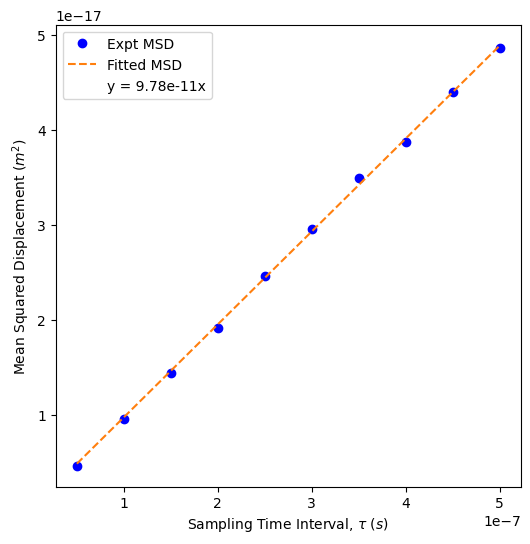

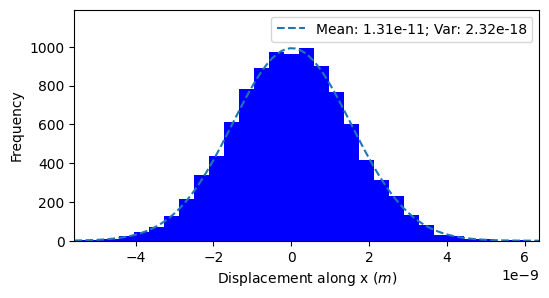

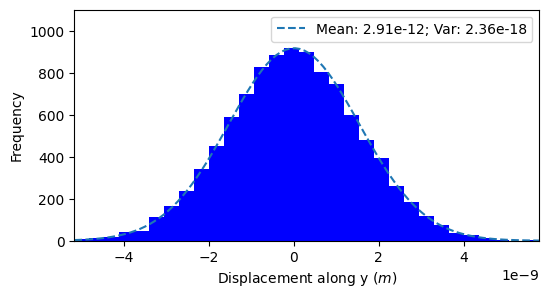

Dmsd: 2.445729009389177e-13 Dvar: 2.340844279204038e-13



In [6]:
dump_file =  'dump' # 'dump.2000'
(
    expmsd_n_Particles, 
    Dvar_of_n_particles, 
    tau_arr, 
    particles, 
    mean_Dmsd_of_n_particles, std_Dmsd_of_n_particles,
    mean_Dvar_of_n_particles, std_Dvar_of_n_particles,
    dr_of_n_Particles, 
    tau
) = main(
    dump_file, 
    total_particles=1, 
    tau=5.00e-08, 
    dump_freq = 100,
    particles=[1], # 2, 3, 4, 5, 6, 7, 8, 9, 10],  #np.random.choicae(np.arange(1, total_particles), size=10, replace=False)
    show=True,
    D_print=True
)
# print(f"Mean Dmsd: {mean_Dmsd_of_n_particles}")
# print(f"Std Dmsd: {std_Dmsd_of_n_particles}")
# print(f"Mean Dvar: {mean_Dvar_of_n_particles}")
# print(f"Std Dvar: {std_Dvar_of_n_particles}")

In [ ]:
# List of your 10 dump file names
dump_files = [
    'dump2.700', '2dump2.700', '3dump2.700', '4dump2.700', '5dump2.700',
    '6dump2.700', '7dump2.700', '8dump2.700', '9dump2.700', '10dump2.700'
]

# Arrays to store diffusion coefficients
Dmsd_list = []
Dvar_list = []

# Loop over all dump files
for dump_file in dump_files:
    (
        expmsd_n_Particles, 
        Dvar_of_n_particles, 
        tau_arr, 
        particles, 
        mean_Dmsd_of_n_particles, std_Dmsd_of_n_particles,
        mean_Dvar_of_n_particles, std_Dvar_of_n_particles,
        dr_of_n_Particles, 
        tau
    ) = main(
        dump_file, 
        total_particles=1, 
        tau=5.00e-08, 
        dump_freq = 700,
        particles=[1],
        show=False,
        D_print=False  # Turn off printing inside `main`
    )

    # Store diffusion coefficients
    Dmsd_list.append(mean_Dmsd_of_n_particles)
    Dvar_list.append(mean_Dvar_of_n_particles)

# Compute stats
def summarize(name, values):
    mean_val = np.mean(values)
    std_val = np.std(values, ddof=1)
    print(f"\n{name} values (µm²/s): {[f'{v:.5e}' for v in values]}")
    print(f"{name} - Mean: {mean_val:.7e}")
    print(f"{name} - Std Dev: {std_val:.7e}")

# Print summary
summarize("Dmsd", np.array(Dmsd_list))
summarize("Dvar", np.array(Dvar_list))


Dmsd values (µm²/s): ['2.45540e-13', '2.61901e-13', '2.29977e-13', '2.05747e-13', '2.74286e-13', '2.28070e-13', '2.34785e-13', '2.36026e-13', '2.68207e-13', '2.66746e-13']
Dmsd - Mean: 2.4512847e-13
Dmsd - Std Dev: 2.2092889e-14

Dvar values (µm²/s): ['2.44891e-13', '2.46774e-13', '2.42236e-13', '2.33404e-13', '2.40529e-13', '2.52296e-13', '2.41171e-13', '2.44332e-13', '2.40030e-13', '2.50376e-13']
Dvar - Mean: 2.4360378e-13
Dvar - Std Dev: 5.4538264e-15


In [ ]:
frame_number = 1
dump_files = [f"{i if i > 1 else ''}dump2.{frame_number}" for i in range(1, 11)]
Dmsd_list = []
Dvar_list = []
for dump_file in dump_files:
    (
        expmsd_n_Particles, 
        Dvar_of_n_particles, 
        tau_arr, 
        particles, 
        mean_Dmsd_of_n_particles, std_Dmsd_of_n_particles,
        mean_Dvar_of_n_particles, std_Dvar_of_n_particles,
        dr_of_n_Particles, 
        tau
    ) = main(
        dump_file, 
        total_particles=1, 
        tau=5.00e-08, 
        dump_freq=frame_number,
        particles=[1],
        show=False,
        D_print=False
    )
    Dmsd_list.append(mean_Dmsd_of_n_particles)
    Dvar_list.append(mean_Dvar_of_n_particles)
def summarize(name, values):
    mean_val = np.mean(values)
    std_val = np.std(values, ddof=1)
    print(f"\n{name} values (µm²/s): {[f'{v:.5e}' for v in values]}")
    print(f"{name} - Mean: {mean_val:.7e}")
    print(f"{name} - Std Dev: {std_val:.7e}")
summarize("Dmsd", np.array(Dmsd_list))
summarize("Dvar", np.array(Dvar_list))


Dmsd values (µm²/s): ['1.24290e-13', '1.24115e-13', '1.25021e-13', '1.24020e-13', '1.24348e-13', '1.23504e-13', '1.23777e-13', '1.24353e-13', '1.23475e-13', '1.24104e-13']
Dmsd - Mean: 1.2410064e-13
Dmsd - Std Dev: 4.5552825e-16

Dvar values (µm²/s): ['2.58763e-14', '2.58722e-14', '2.60043e-14', '2.58414e-14', '2.59088e-14', '2.57698e-14', '2.58238e-14', '2.59046e-14', '2.57695e-14', '2.58706e-14']
Dvar - Mean: 2.5864125e-14
Dvar - Std Dev: 6.9534775e-17


In [ ]:
frame_number = 2
dump_files = [f"{i if i > 1 else ''}dump2.{frame_number}" for i in range(1, 11)]
Dmsd_list = []
Dvar_list = []
for dump_file in dump_files:
    (
        expmsd_n_Particles, 
        Dvar_of_n_particles, 
        tau_arr, 
        particles, 
        mean_Dmsd_of_n_particles, std_Dmsd_of_n_particles,
        mean_Dvar_of_n_particles, std_Dvar_of_n_particles,
        dr_of_n_Particles, 
        tau
    ) = main(
        dump_file, 
        total_particles=1, 
        tau=5.00e-08, 
        dump_freq=frame_number,
        particles=[1],
        show=False,
        D_print=False
    )
    Dmsd_list.append(mean_Dmsd_of_n_particles)
    Dvar_list.append(mean_Dvar_of_n_particles)
def summarize(name, values):
    mean_val = np.mean(values)
    std_val = np.std(values, ddof=1)
    print(f"\n{name} values (µm²/s): {[f'{v:.5e}' for v in values]}")
    print(f"{name} - Mean: {mean_val:.7e}")
    print(f"{name} - Std Dev: {std_val:.7e}")
summarize("Dmsd", np.array(Dmsd_list))
summarize("Dvar", np.array(Dvar_list))


Dmsd values (µm²/s): ['1.71134e-13', '1.70894e-13', '1.72163e-13', '1.70771e-13', '1.71077e-13', '1.70351e-13', '1.69564e-13', '1.70940e-13', '1.69622e-13', '1.70655e-13']
Dmsd - Mean: 1.7071707e-13
Dmsd - Std Dev: 7.5611439e-16

Dvar values (µm²/s): ['4.68208e-14', '4.68071e-14', '4.70787e-14', '4.67504e-14', '4.68702e-14', '4.66050e-14', '4.67105e-14', '4.68758e-14', '4.66099e-14', '4.68057e-14']
Dvar - Mean: 4.6793406e-14
Dvar - Std Dev: 1.3868279e-16


In [ ]:
frame_number = 3
dump_files = [f"{i if i > 1 else ''}dump2.{frame_number}" for i in range(1, 11)]
Dmsd_list = []
Dvar_list = []
for dump_file in dump_files:
    (
        expmsd_n_Particles, 
        Dvar_of_n_particles, 
        tau_arr, 
        particles, 
        mean_Dmsd_of_n_particles, std_Dmsd_of_n_particles,
        mean_Dvar_of_n_particles, std_Dvar_of_n_particles,
        dr_of_n_Particles, 
        tau
    ) = main(
        dump_file, 
        total_particles=1, 
        tau=5.00e-08, 
        dump_freq=frame_number,
        particles=[1],
        show=False,
        D_print=False
    )
    Dmsd_list.append(mean_Dmsd_of_n_particles)
    Dvar_list.append(mean_Dvar_of_n_particles)
def summarize(name, values):
    mean_val = np.mean(values)
    std_val = np.std(values, ddof=1)
    print(f"\n{name} values (µm²/s): {[f'{v:.5e}' for v in values]}")
    print(f"{name} - Mean: {mean_val:.7e}")
    print(f"{name} - Std Dev: {std_val:.7e}")
summarize("Dmsd", np.array(Dmsd_list))
summarize("Dvar", np.array(Dvar_list))


Dmsd values (µm²/s): ['1.92998e-13', '1.92798e-13', '1.94428e-13', '1.92426e-13', '1.93434e-13', '1.92324e-13', '1.91270e-13', '1.93299e-13', '1.91417e-13', '1.92637e-13']
Dmsd - Mean: 1.9270288e-13
Dmsd - Std Dev: 9.3646734e-16

Dvar values (µm²/s): ['6.50899e-14', '6.50854e-14', '6.54784e-14', '6.49783e-14', '6.51792e-14', '6.47712e-14', '6.49434e-14', '6.51879e-14', '6.47887e-14', '6.50858e-14']
Dvar - Mean: 6.5058808e-14
Dvar - Std Dev: 2.0685016e-16


In [ ]:
frame_number = 4
dump_files = [f"{i if i > 1 else ''}dump2.{frame_number}" for i in range(1, 11)]
Dmsd_list = []
Dvar_list = []
for dump_file in dump_files:
    (
        expmsd_n_Particles, 
        Dvar_of_n_particles, 
        tau_arr, 
        particles, 
        mean_Dmsd_of_n_particles, std_Dmsd_of_n_particles,
        mean_Dvar_of_n_particles, std_Dvar_of_n_particles,
        dr_of_n_Particles, 
        tau
    ) = main(
        dump_file, 
        total_particles=1, 
        tau=5.00e-08, 
        dump_freq=frame_number,
        particles=[1],
        show=False,
        D_print=False
    )
    Dmsd_list.append(mean_Dmsd_of_n_particles)
    Dvar_list.append(mean_Dvar_of_n_particles)
def summarize(name, values):
    mean_val = np.mean(values)
    std_val = np.std(values, ddof=1)
    print(f"\n{name} values (µm²/s): {[f'{v:.5e}' for v in values]}")
    print(f"{name} - Mean: {mean_val:.7e}")
    print(f"{name} - Std Dev: {std_val:.7e}")
summarize("Dmsd", np.array(Dmsd_list))
summarize("Dvar", np.array(Dvar_list))


Dmsd values (µm²/s): ['2.05699e-13', '2.05786e-13', '2.07016e-13', '2.05301e-13', '2.05773e-13', '2.05609e-13', '2.02838e-13', '2.05404e-13', '2.03312e-13', '2.04763e-13']
Dmsd - Mean: 2.0515006e-13
Dmsd - Std Dev: 1.2358680e-15

Dvar values (µm²/s): ['8.10874e-14', '8.10237e-14', '8.16029e-14', '8.09770e-14', '8.11931e-14', '8.06955e-14', '8.09003e-14', '8.12259e-14', '8.07001e-14', '8.10655e-14']
Dvar - Mean: 8.1047138e-14
Dvar - Std Dev: 2.6566572e-16


In [ ]:
frame_number = 5
dump_files = [f"{i if i > 1 else ''}dump2.{frame_number}" for i in range(1, 11)]
Dmsd_list = []
Dvar_list = []
for dump_file in dump_files:
    (
        expmsd_n_Particles, 
        Dvar_of_n_particles, 
        tau_arr, 
        particles, 
        mean_Dmsd_of_n_particles, std_Dmsd_of_n_particles,
        mean_Dvar_of_n_particles, std_Dvar_of_n_particles,
        dr_of_n_Particles, 
        tau
    ) = main(
        dump_file, 
        total_particles=1, 
        tau=5.00e-08, 
        dump_freq=frame_number,
        particles=[1],
        show=False,
        D_print=False
    )
    Dmsd_list.append(mean_Dmsd_of_n_particles)
    Dvar_list.append(mean_Dvar_of_n_particles)
def summarize(name, values):
    mean_val = np.mean(values)
    std_val = np.std(values, ddof=1)
    print(f"\n{name} values (µm²/s): {[f'{v:.5e}' for v in values]}")
    print(f"{name} - Mean: {mean_val:.7e}")
    print(f"{name} - Std Dev: {std_val:.7e}")
summarize("Dmsd", np.array(Dmsd_list))
summarize("Dvar", np.array(Dvar_list))


Dmsd values (µm²/s): ['2.13697e-13', '2.13143e-13', '2.14212e-13', '2.12716e-13', '2.13684e-13', '2.13593e-13', '2.10738e-13', '2.13144e-13', '2.10524e-13', '2.13048e-13']
Dmsd - Mean: 2.1284991e-13
Dmsd - Std Dev: 1.2436985e-15

Dvar values (µm²/s): ['9.51050e-14', '9.50736e-14', '9.57002e-14', '9.49832e-14', '9.53017e-14', '9.46265e-14', '9.49067e-14', '9.52759e-14', '9.46185e-14', '9.50632e-14']
Dvar - Mean: 9.5065440e-14
Dvar - Std Dev: 3.2130018e-16
